<a href="https://colab.research.google.com/github/Mikhailo88/MN-Praktychni-K4/blob/main/%D0%9B%D0%A0_8_%D0%9E%D0%BB%D1%8C%D1%85%D0%BE%D0%B2%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A24_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import scipy

from sklearn.datasets import load_iris, load_wine, make_blobs, make_moons
from sklearn.decomposition import PCA
from sklearn.cluster import (
    KMeans, MiniBatchKMeans, BisectingKMeans,
    AgglomerativeClustering, DBSCAN, OPTICS, HDBSCAN,
    MeanShift, estimate_bandwidth, AffinityPropagation,
    Birch, SpectralClustering,
)
from sklearn.mixture import GaussianMixture, BayesianGaussianMixture
from sklearn.metrics import (
    silhouette_score, silhouette_samples,
    calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, adjusted_mutual_info_score,
)
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import euclidean, cityblock, cosine

RANDOM_STATE = 42
pd.set_option('display.max_columns', 15)
plt.rcParams.update({'figure.figsize': (8, 5), 'axes.grid': True,
                     'grid.alpha': 0.20, 'font.size': 10})

print('scikit-learn:', sklearn.__version__)
print('NumPy:', np.__version__)
print('SciPy:', scipy.__version__)

import os

scikit-learn: 1.6.1
NumPy: 2.4.6
SciPy: 1.16.3


**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [46]:
Iris = load_iris()
X = Iris.data

pd.DataFrame(X, columns=iris.feature_names).head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

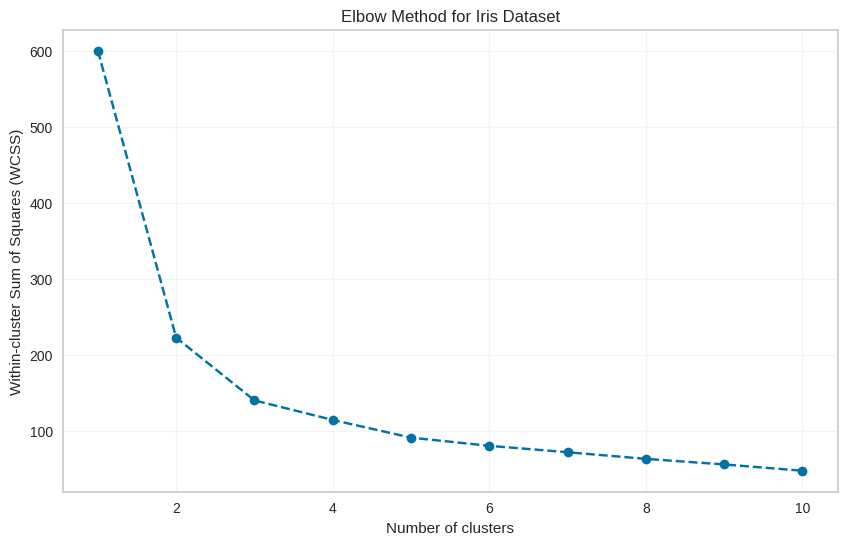

In [48]:
# Масштабування даних
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_iris = pd.DataFrame(X_scaled, columns=iris.feature_names)

# Метод ліктя
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++',
                    max_iter=300, n_init=10, random_state=0)
    kmeans.fit(X_iris)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Iris Dataset')
plt.xlabel('Number of clusters')
plt.ylabel('Within-cluster Sum of Squares (WCSS)')
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

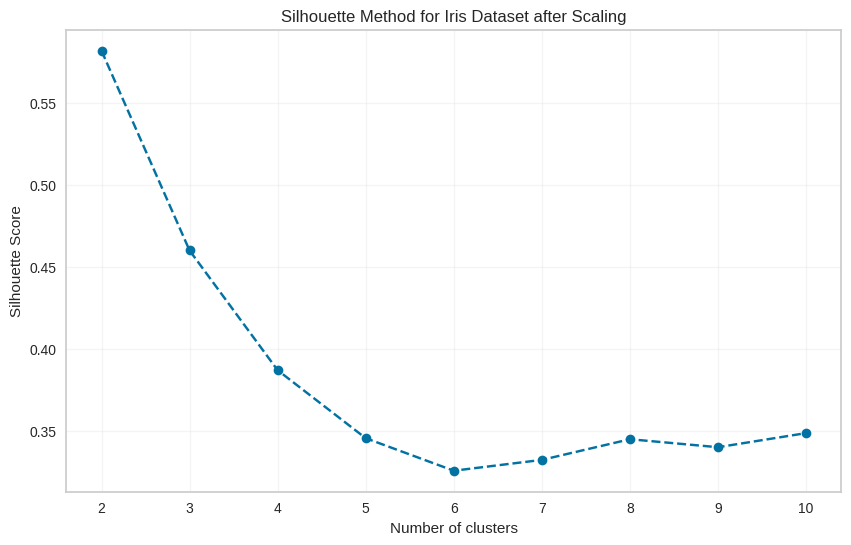

In [50]:
# Застосування методу силуетів для визначення оптимальної кількості кластерів
silhouette_scores = []

for i in range(2, 11):  # Для методу силуетів потрібно мінімум 2 кластери
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=0)
    cluster_labels = kmeans.fit_predict(X_iris)
    silhouette_avg = silhouette_score(X_iris, cluster_labels)
    silhouette_scores.append(silhouette_avg)

# Візуалізація графіка методу силуетів
plt.figure(figsize=(10, 6))
plt.plot(range(2, 11), silhouette_scores, marker='o', linestyle='--')
plt.title('Silhouette Method for Iris Dataset after Scaling')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

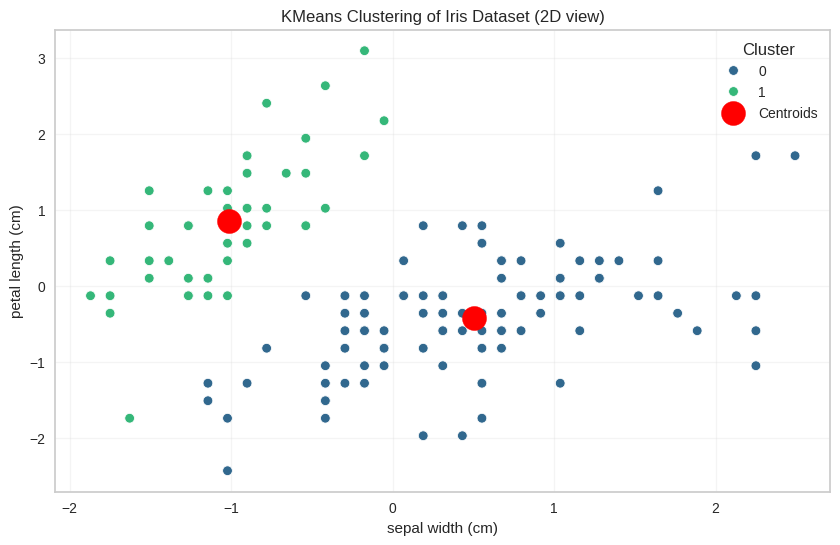

In [51]:
# K-Means на тих самих ознаках, що й метод ліктя та силуета
kmeans = KMeans(n_clusters=2, init='k-means++', max_iter=300, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_iris)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_iris.iloc[:, 0], y=X_iris.iloc[:, 1], hue=clusters,
                palette='viridis', legend='full')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            s=300, c='red', label='Centroids')

plt.title('KMeans Clustering of Iris Dataset (2D view)')
plt.xlabel(iris.feature_names[1])
plt.ylabel(iris.feature_names[2])
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [29]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [11]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [10]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**Опис даних**

1. StudentID (Ідентифікатор учня) — унікальний номер кожного учня, який використовується для його ідентифікації в наборі даних.

2. Age (Вік) — вік учня в роках. Дозволяє досліджувати залежність навчальних результатів від віку.

3. Gender (Стать) — стать учня, закодована числовим значенням. Використовується для аналізу відмінностей у навчальних результатах.

4. Ethnicity (Етнічна приналежність) — категорія етнічної приналежності учня, представлена числовим кодом.

5. ParentalEducation (Освіта батьків) — рівень освіти батьків учня. Дає змогу дослідити, чи впливає освіта батьків на успішність дитини.

6. StudyTimeWeekly (Щотижневий час навчання) — кількість годин, які учень витрачає на самостійне навчання протягом тижня.

7. Absences (Пропуски занять) — кількість пропущених учнем навчальних занять. Може впливати на засвоєння матеріалу та підсумкову успішність.

8. Tutoring (Додаткові заняття) — показник участі учня в додаткових заняттях або репетиторстві. Дозволяє оцінити вплив додаткової допомоги на результати навчання.

9. ParentalSupport (Підтримка батьків) — рівень підтримки, яку батьки надають учневі в навчанні. Може відображати зацікавленість батьків у його освіті.

10. Extracurricular (Позакласна діяльність) — показник участі учня в різноманітних позакласних заходах, гуртках та інших активностях.

11. Sports (Спорт) — показник участі учня у спортивних заняттях або секціях. Дає змогу дослідити зв'язок фізичної активності з навчальною успішністю.

12. Music (Музика) — показник участі учня в музичних заняттях або діяльності, пов'язаній із музикою.

13. Volunteering (Волонтерство) — показник участі учня у волонтерській діяльності та громадських ініціативах.

14. GPA (Середній бал) — середній академічний бал учня, який характеризує його загальну успішність за навчальними предметами.

15. GradeClass (Клас успішності) — цільова змінна, яка визначає категорію академічної успішності учня на основі його середнього бала GPA. Використовується для побудови моделі класифікації.

**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [18]:
print(df.columns.tolist())

['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [20]:
print(df.isnull().sum())

StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [22]:
duplicates = df.duplicated().sum()

print("Кількість дублікатів:", duplicates)

Кількість дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [23]:
display(df.describe())

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [26]:
# Формування ознак і цільової змінної
X = df.drop(columns=["GradeClass", "StudentID"])
y = df["GradeClass"]

# Поділ даних на навчальну і тестову вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Стандартизація ознак
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Розмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

Розмір навчальної вибірки: (1913, 13)
Розмір тестової вибірки: (479, 13)


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [30]:
# Створення моделі
rf = RandomForestClassifier(random_state=42)

# Сітка гіперпараметрів
rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

# Пошук найкращих параметрів
rf_grid = GridSearchCV(
    estimator=rf,
    param_grid=rf_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

rf_grid.fit(X_train_scaled, y_train)

# Результати
rf_best = rf_grid.best_estimator_
rf_pred = rf_best.predict(X_test_scaled)

print("Найкращі параметри Random Forest:")
print(rf_grid.best_params_)

print("\nСередня CV-точність:")
print(round(rf_grid.best_score_, 4))

print("\nТестова Accuracy:")
print(round(accuracy_score(y_test, rf_pred), 4))

Найкращі параметри Random Forest:
{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}

Середня CV-точність:
0.9211

Тестова Accuracy:
0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [31]:
# Створення моделі
lr = LogisticRegression(
    solver="saga",
    random_state=42
)

# Сітка гіперпараметрів
lr_params = {
    "C": [0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
    "max_iter": [1000, 2000]
}

# Пошук найкращих параметрів
lr_grid = GridSearchCV(
    estimator=lr,
    param_grid=lr_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

lr_grid.fit(X_train_scaled, y_train)

# Результати
lr_best = lr_grid.best_estimator_
lr_pred = lr_best.predict(X_test_scaled)

print("Найкращі параметри Logistic Regression:")
print(lr_grid.best_params_)

print("\nСередня CV-точність:")
print(round(lr_grid.best_score_, 4))

print("\nТестова Accuracy:")
print(round(accuracy_score(y_test, lr_pred), 4))

Найкращі параметри Logistic Regression:
{'C': 0.1, 'max_iter': 1000, 'penalty': 'l1'}

Середня CV-точність:
0.8024

Тестова Accuracy:
0.8184


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [32]:
# Створення моделі
svm = SVC()

# Сітка гіперпараметрів
svm_params = {
    "C": [0.1, 1, 10, 100],
    "kernel": ["linear", "rbf"],
    "gamma": ["scale", "auto"]
}

# Пошук найкращих параметрів
svm_grid = GridSearchCV(
    estimator=svm,
    param_grid=svm_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

svm_grid.fit(X_train_scaled, y_train)

# Результати
svm_best = svm_grid.best_estimator_
svm_pred = svm_best.predict(X_test_scaled)

print("Найкращі параметри SVM:")
print(svm_grid.best_params_)

print("\nСередня CV-точність:")
print(round(svm_grid.best_score_, 4))

print("\nТестова Accuracy:")
print(round(accuracy_score(y_test, svm_pred), 4))

Найкращі параметри SVM:
{'C': 100, 'gamma': 'scale', 'kernel': 'linear'}

Середня CV-точність:
0.8547

Тестова Accuracy:
0.8497


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [33]:
results = pd.DataFrame({
    "Модель": ["Random Forest", "Logistic Regression", "SVM"],
    "CV Accuracy": [
        rf_grid.best_score_,
        lr_grid.best_score_,
        svm_grid.best_score_
    ],
    "Test Accuracy": [
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, svm_pred)
    ]
})

results = results.sort_values(
    by="CV Accuracy",
    ascending=False
).reset_index(drop=True)

display(results.round(4))

# Вибір найкращої моделі за CV Accuracy
best_name = results.loc[0, "Модель"]

models = {
    "Random Forest": rf_best,
    "Logistic Regression": lr_best,
    "SVM": svm_best
}

best_model = models[best_name]
y_pred_best = best_model.predict(X_test_scaled)

print("Найкраща модель:", best_name)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

,Модель,CV Accuracy,Test Accuracy
0,Random Forest,0.9211,0.9102
1,SVM,0.8547,0.8497
2,Logistic Regression,0.8024,0.8184


Найкраща модель: Random Forest

Classification Report:
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

In [34]:
# Вибір чотирьох ознак
cluster_features = ["Age", "StudyTimeWeekly", "Absences", "GPA"]

X_cluster = df[cluster_features]

# Стандартизація
cluster_scaler = StandardScaler()
X_cluster_scaled = cluster_scaler.fit_transform(X_cluster)

print("Розмірність даних:", X_cluster_scaled.shape)

Розмірність даних: (2392, 4)


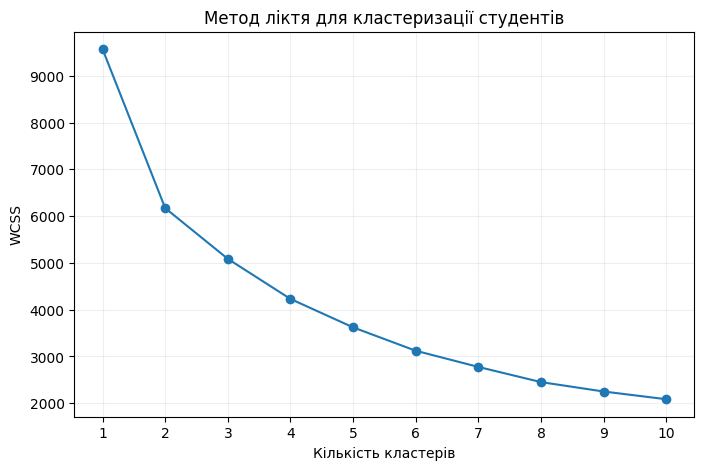

In [35]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_cluster_scaled)
    wcss.append(kmeans.inertia_)

# Побудова графіка
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")

plt.title("Метод ліктя для кластеризації студентів")
plt.xlabel("Кількість кластерів")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

Кількість кластерів: 2, Silhouette: 0.3080
Кількість кластерів: 3, Silhouette: 0.2702
Кількість кластерів: 4, Silhouette: 0.2580
Кількість кластерів: 5, Silhouette: 0.2645
Кількість кластерів: 6, Silhouette: 0.2689
Кількість кластерів: 7, Silhouette: 0.2692
Кількість кластерів: 8, Silhouette: 0.2712
Кількість кластерів: 9, Silhouette: 0.2732
Кількість кластерів: 10, Silhouette: 0.2725


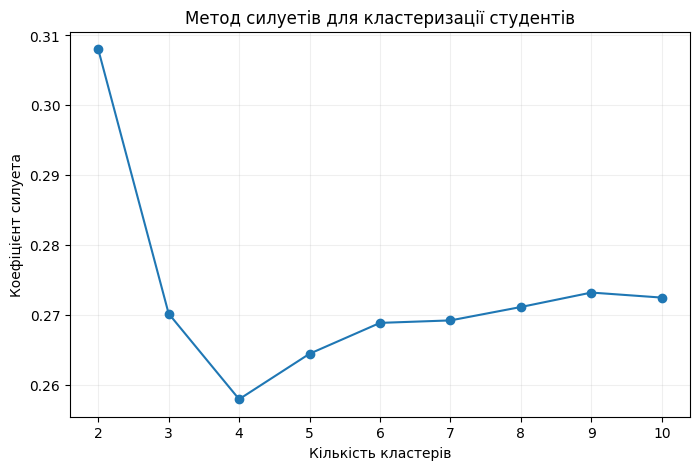

Найкраща кількість кластерів за силуетом: 2


In [36]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_cluster_scaled)

    score = silhouette_score(X_cluster_scaled, labels)
    silhouette_scores.append(score)

    print(f"Кількість кластерів: {k}, Silhouette: {score:.4f}")

# Побудова графіка
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker="o")

plt.title("Метод силуетів для кластеризації студентів")
plt.xlabel("Кількість кластерів")
plt.ylabel("Коефіцієнт силуета")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

# Найкраща кількість кластерів
best_silhouette_k = silhouette_scores.index(max(silhouette_scores)) + 2

print("Найкраща кількість кластерів за силуетом:", best_silhouette_k)

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [37]:
!pip install -q kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [38]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from kneed import KneeLocator
from yellowbrick.cluster import KElbowVisualizer

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [39]:
# Вибір усіх ознак, крім StudentID та GradeClass
X_pca = df.drop(columns=["StudentID", "GradeClass"])

# Стандартизація
pca_scaler = StandardScaler()
X_pca_scaled = pca_scaler.fit_transform(X_pca)

print("Розмірність початкових даних:", X_pca.shape)
print("Розмірність після стандартизації:", X_pca_scaled.shape)

Розмірність початкових даних: (2392, 13)
Розмірність після стандартизації: (2392, 13)


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [40]:
pca = PCA()

X_pca_transformed = pca.fit_transform(X_pca_scaled)

explained_variance = pca.explained_variance_ratio_

print("Частка поясненої дисперсії компонент:")
print(explained_variance)

Частка поясненої дисперсії компонент:
[0.15246911 0.0861136  0.08267885 0.08071826 0.07864825 0.07793075
 0.0763079  0.07600434 0.07440892 0.0737979  0.07167781 0.06746103
 0.00178329]


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

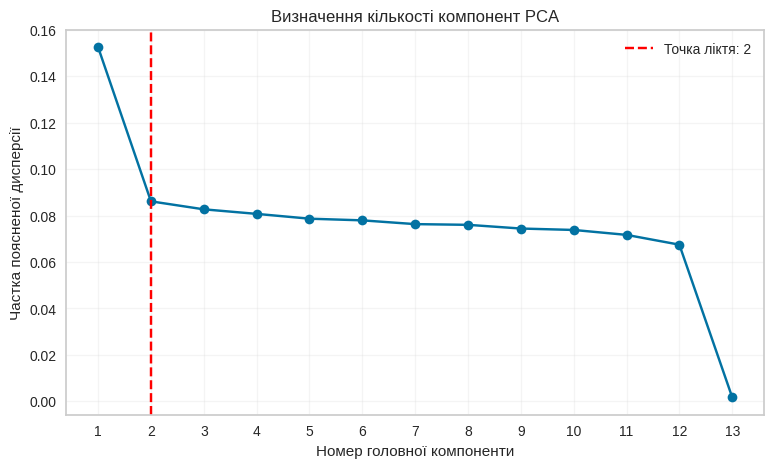

Оптимальна кількість компонент: 2


In [41]:
components = np.arange(1, len(explained_variance) + 1)

knee_locator = KneeLocator(
    components,
    explained_variance,
    curve="convex",
    direction="decreasing"
)

optimal_components = knee_locator.knee

# Побудова графіка
plt.figure(figsize=(9, 5))
plt.plot(components, explained_variance, marker="o")
plt.axvline(
    x=optimal_components,
    color="red",
    linestyle="--",
    label=f"Точка ліктя: {optimal_components}"
)

plt.title("Визначення кількості компонент PCA")
plt.xlabel("Номер головної компоненти")
plt.ylabel("Частка поясненої дисперсії")
plt.xticks(components)
plt.grid(True)
plt.legend()
plt.show()

print("Оптимальна кількість компонент:", optimal_components)

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

Кількість вибраних компонент: 2
Кумулятивна пояснена дисперсія: 0.2386


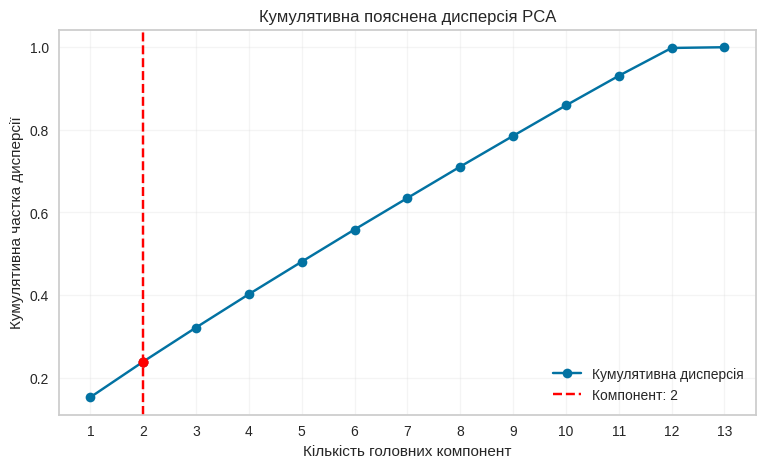

In [42]:
# Кумулятивна пояснена дисперсія
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(9, 5))
plt.plot(
    components,
    cumulative_variance,
    marker="o",
    label="Кумулятивна дисперсія"
)

if optimal_components is not None:
    selected_variance = cumulative_variance[optimal_components - 1]

    plt.axvline(
        x=optimal_components,
        color="red",
        linestyle="--",
        label=f"Компонент: {optimal_components}"
    )

    plt.scatter(
        optimal_components,
        selected_variance,
        color="red",
        zorder=3
    )

    print("Кількість вибраних компонент:", optimal_components)
    print("Кумулятивна пояснена дисперсія:", round(selected_variance, 4))

plt.title("Кумулятивна пояснена дисперсія PCA")
plt.xlabel("Кількість головних компонент")
plt.ylabel("Кумулятивна частка дисперсії")
plt.xticks(components)
plt.grid(True)
plt.legend()
plt.show()

In [43]:
if optimal_components is None:
    raise ValueError("KneeLocator не зміг визначити точку ліктя.")

pca_final = PCA(n_components=optimal_components)

X_pca_final = pca_final.fit_transform(X_pca_scaled)

print("Розмірність даних після PCA:", X_pca_final.shape)
print(
    "Загальна пояснена дисперсія:",
    round(pca_final.explained_variance_ratio_.sum(), 4)
)

Розмірність даних після PCA: (2392, 2)
Загальна пояснена дисперсія: 0.2386


Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [44]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

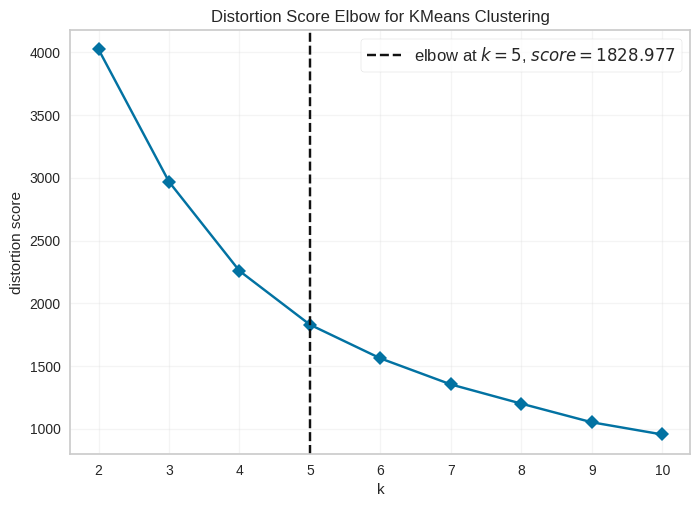

Оптимальна кількість кластерів після PCA: 5


In [45]:
kmeans_pca = KMeans(
    random_state=42,
    n_init=10
)

visualizer = KElbowVisualizer(
    kmeans_pca,
    k=(2, 11),
    metric="distortion",
    timings=False
)

visualizer.fit(X_pca_final)
visualizer.show()

print("Оптимальна кількість кластерів після PCA:", visualizer.elbow_value_)

## Висновки

У ході лабораторної роботи було проведено класифікацію та кластеризацію даних про успішність студентів. Дані поділено на навчальну вибірку (1913 записів) і тестову (479 записів).

Серед трьох моделей найкращий результат показала Random Forest з CV Accuracy 0.9211 та Test Accuracy 0.9102. SVM отримала 0.8547 та 0.8497 відповідно, а Logistic Regression — 0.8024 та 0.8184. Отже, Random Forest найкраще класифікує студентів за рівнем успішності.

Для кластеризації було використано ознаки Age, StudyTimeWeekly, Absences та GPA. За методом силуетів найкращою кількістю виявилися 2 кластери з коефіцієнтом 0.3080. Методи ліктя та силуетів дозволили оцінити оптимальну кількість груп.

Додатково було застосовано PCA, за допомогою якого обрано 2 головні компоненти, що пояснюють 23.86% дисперсії початкових даних.

Отже, класифікація використовує відому цільову змінну GradeClass для прогнозування успішності, тоді як кластеризація працює без неї та самостійно об'єднує студентів у групи за схожими характеристиками. У результаті було досліджено різні алгоритми машинного навчання та визначено найкращу модель класифікації — Random Forest.